# Customer Churn Prediction — Telco Dataset

**Goal:** predict whether a telecom customer will churn, so the retention team
can intervene with targeted offers.

**Approach:** exploratory data analysis → feature engineering (missing-value
handling + categorical encoding in a reusable sklearn `ColumnTransformer`) →
a tuned `RandomForestClassifier` → evaluation and churn-driver analysis.

> The tuned hyperparameters below come from the grid search in `src/train.py`
> (see `models/metrics.json`), so the notebook mirrors the production model.

In [1]:
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

sys.path.insert(0, os.path.abspath("../src"))
from data_loader import TARGET_COLUMN, load_data, prepare_frame
from features import FEATURE_COLUMNS, build_preprocessor, get_feature_names

df = prepare_frame(load_data("../data/telco_customer_churn.csv"))
print("shape:", df.shape)

shape: (7043, 21)


## 1. Dataset overview

The IBM Telco Customer Churn dataset: 7,043 customers, 20 predictors plus the
`Churn` target (26.5% churn rate). Predictors cover demographics, account
tenure, subscribed services, contract type, billing, and charges.

In [2]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [3]:
print(df.dtypes.to_string())
print()
print(df.describe(include="all").T[["count", "unique", "mean", "min", "max"]].to_string())

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64

                   count unique         mean    min     max
customerID          7043   7043          NaN    NaN     NaN
gender              7043      2          NaN    NaN     NaN
SeniorCitizen     7043.0    NaN     0.162147    0.0     1.0
Partner             7043      2          NaN    NaN     NaN
Dependents          7043      2          NaN    NaN     NaN
tenure            7043.0    NaN    32.371149    0.0

## 2. Missing values

`TotalCharges` is stored as a blank string for 11 brand-new customers
(`tenure == 0`), which `prepare_frame` converts to `NaN`. No other column has
missing values. The pipeline below imputes `TotalCharges` with the **training
median** — statistics are never fit on the test split, so there is no leakage.

In [4]:
missing = df.isna().sum()
print(missing[missing > 0].to_string())
print()
print(df.loc[df["TotalCharges"].isna(), ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]].head(11).to_string())

TotalCharges    11

      tenure  MonthlyCharges  TotalCharges  Churn
488        0           52.55           NaN      0
753        0           20.25           NaN      0
936        0           80.85           NaN      0
1082       0           25.75           NaN      0
1340       0           56.05           NaN      0
3331       0           19.85           NaN      0
3826       0           25.35           NaN      0
4380       0           20.00           NaN      0
5218       0           19.70           NaN      0
6670       0           73.35           NaN      0
6754       0           61.90           NaN      0


## 3. Exploratory data analysis

/tmp/ipykernel_5743/4259481133.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Churn", ax=axes[0], palette="Blues_d")
/tmp/ipykernel_5743/4259481133.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(["No (stay)", "Yes (churn)"])
/tmp/ipykernel_5743/4259481133.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=churn_by_contract.index, y=churn_by_contract.values, ax=axes[1], palette="Reds_d")


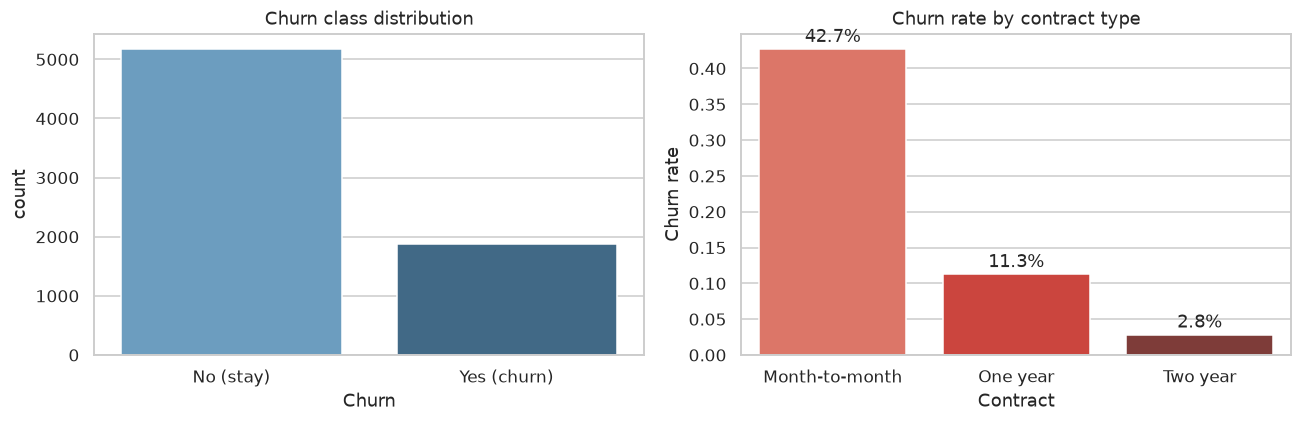

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="Churn", ax=axes[0], palette="Blues_d")
axes[0].set_title("Churn class distribution")
axes[0].set_xticklabels(["No (stay)", "Yes (churn)"])

churn_by_contract = df.groupby("Contract")["Churn"].mean().sort_values(ascending=False)
sns.barplot(x=churn_by_contract.index, y=churn_by_contract.values, ax=axes[1], palette="Reds_d")
axes[1].set_title("Churn rate by contract type")
axes[1].set_ylabel("Churn rate")
for i, v in enumerate(churn_by_contract.values):
    axes[1].text(i, v + 0.01, f"{v:.1%}", ha="center")
plt.tight_layout()
plt.show()

/tmp/ipykernel_5743/497640524.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1], palette="muted")
/tmp/ipykernel_5743/497640524.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(["No (stay)", "Yes (churn)"])


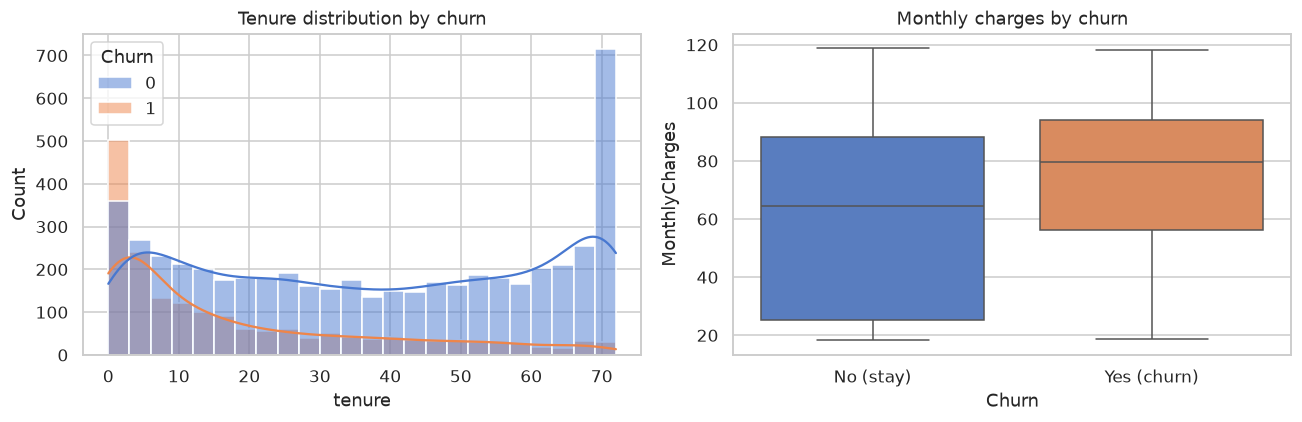

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="tenure", hue="Churn", bins=24, kde=True, ax=axes[0], palette="muted")
axes[0].set_title("Tenure distribution by churn")

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1], palette="muted")
axes[1].set_title("Monthly charges by churn")
axes[1].set_xticklabels(["No (stay)", "Yes (churn)"])
plt.tight_layout()
plt.show()

/tmp/ipykernel_5743/2855138922.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rates.index, y=rates.values, ax=ax, palette="viridis")
/tmp/ipykernel_5743/2855138922.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rates.index, y=rates.values, ax=ax, palette="viridis")
/tmp/ipykernel_5743/2855138922.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rates.index, y=rates.values, ax=ax, palette="viridis")
/tmp/ipykernel_5743/2855138922.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be remov

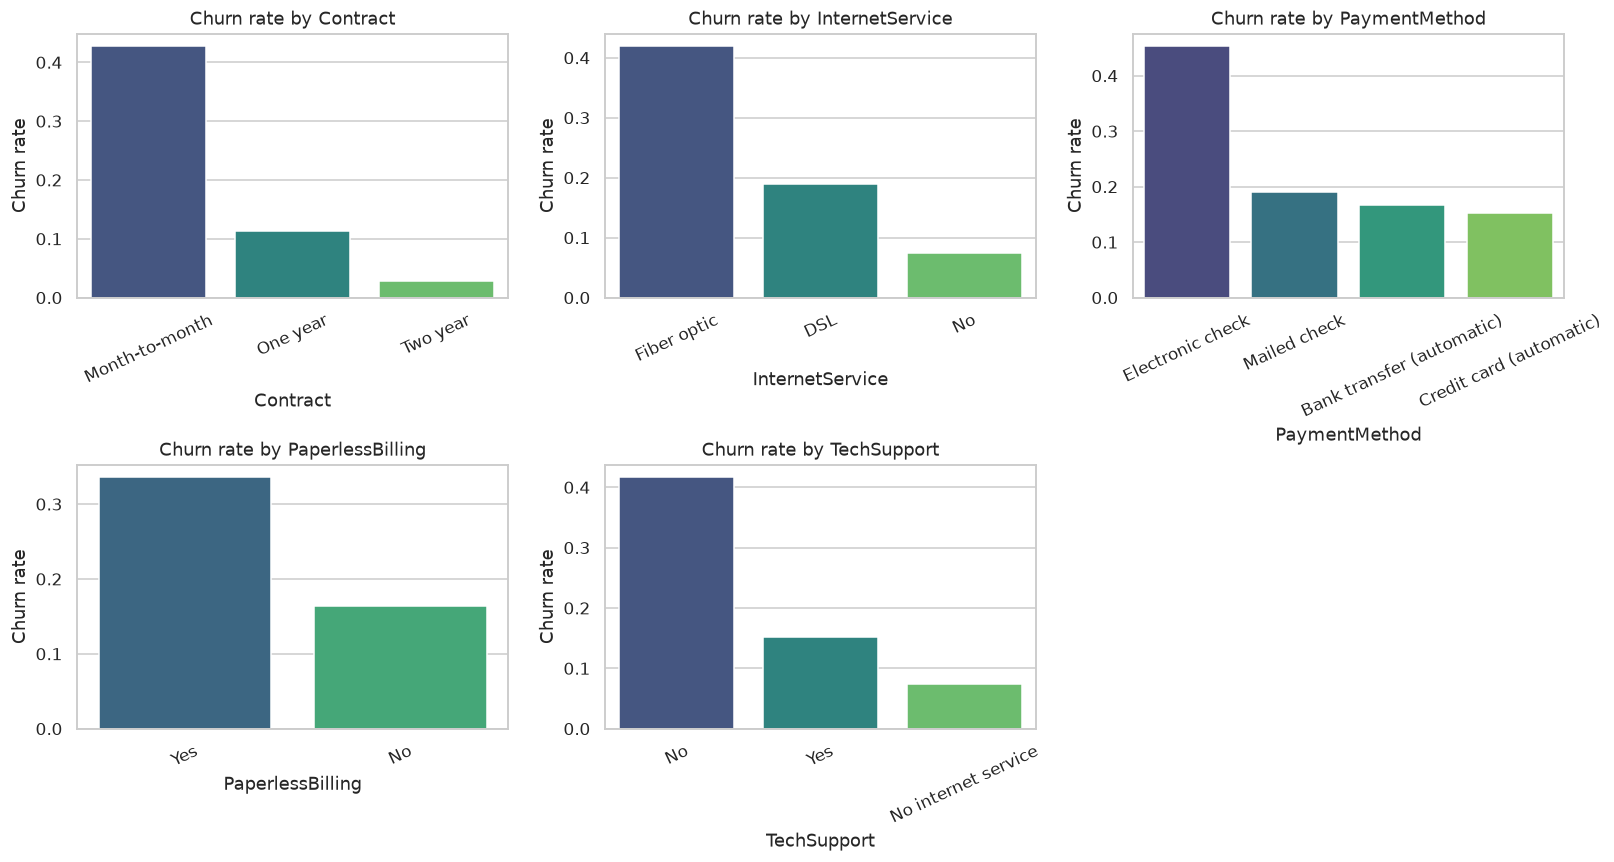

In [7]:
key_drivers = ["Contract", "InternetService", "PaymentMethod", "PaperlessBilling", "TechSupport"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()
for ax, col in zip(axes, key_drivers):
    rates = df.groupby(col)["Churn"].mean().sort_values(ascending=False)
    sns.barplot(x=rates.index, y=rates.values, ax=ax, palette="viridis")
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate")
    ax.tick_params(axis="x", rotation=25)
axes[-1].axis("off")
plt.tight_layout()
plt.show()

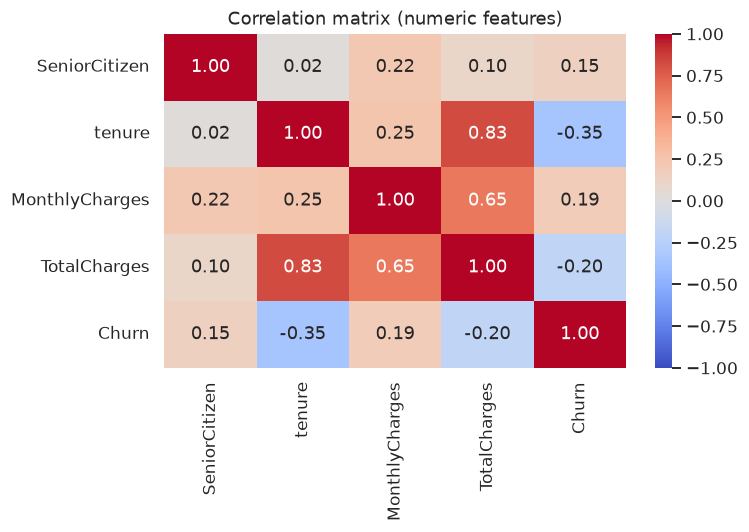

In [8]:
num_cols = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix (numeric features)")
plt.tight_layout()
plt.show()

**EDA takeaways**
- Churn is heavily concentrated in **month-to-month contracts** (~42% churn vs ~3% for two-year contracts).
- **Short tenure** and **higher monthly charges** are strong churn signals.
- **Fiber optic** internet, **electronic check** payment, and **paperless billing**
  customers churn more; add-on services (TechSupport, OnlineSecurity) correlate
  with retention.
- `TotalCharges` correlates strongly with `tenure` (as expected).

## 4. Feature engineering

A single `ColumnTransformer` (defined in `src/features.py`) is used both here
and in production code (`src/train.py`, `src/predict.py`):

- **Numeric** (`SeniorCitizen`, `tenure`, `MonthlyCharges`, `TotalCharges`):
  median imputation → standard scaling.
- **Categorical** (15 columns): most-frequent imputation → one-hot encoding
  (`handle_unknown="ignore"` so inference is robust to unseen categories).
- `customerID` is dropped (pure identifier, no signal).

In [9]:
from sklearn.model_selection import train_test_split

X = df[FEATURE_COLUMNS]
y = df[TARGET_COLUMN]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"train={len(X_train)}  test={len(X_test)}")

preprocessor = build_preprocessor()
X_train_t = preprocessor.fit_transform(X_train)   # fit on train only
X_test_t = preprocessor.transform(X_test)
print("transformed train shape:", X_train_t.shape)

feature_names = get_feature_names(preprocessor)
print(f"{len(feature_names)} model features after one-hot encoding")

train=5634  test=1409
transformed train shape: (5634, 45)
45 model features after one-hot encoding


## 5. Modeling — tuned Random Forest

`src/train.py` ran a `GridSearchCV` (3-fold CV, F1 scoring) over
`n_estimators`, `max_depth`, `min_samples_leaf`, and `class_weight`. The
winning configuration below is reused here so notebook metrics match
`models/metrics.json`.

In [10]:
from sklearn.ensemble import RandomForestClassifier

print("Tuned hyperparameters (from src/train.py grid search):")
BEST_PARAMS = {'class_weight': 'balanced', 'max_depth': 15, 'min_samples_leaf': 2, 'n_estimators': 300}
print(BEST_PARAMS)

model = RandomForestClassifier(random_state=42, n_jobs=-1, **BEST_PARAMS)
model.fit(X_train_t, y_train)

Tuned hyperparameters (from src/train.py grid search):
{'class_weight': 'balanced', 'max_depth': 15, 'min_samples_leaf': 2, 'n_estimators': 300}


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_feat

## 6. Evaluation on the held-out test set

In [11]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             RocCurveDisplay)

y_pred = model.predict(X_test_t)
y_proba = model.predict_proba(X_test_t)[:, 1]

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_proba),
}
print(pd.Series(metrics).round(4).to_string())

Accuracy     0.7622
Precision    0.5396
Recall       0.7112
F1           0.6136
ROC-AUC      0.8351


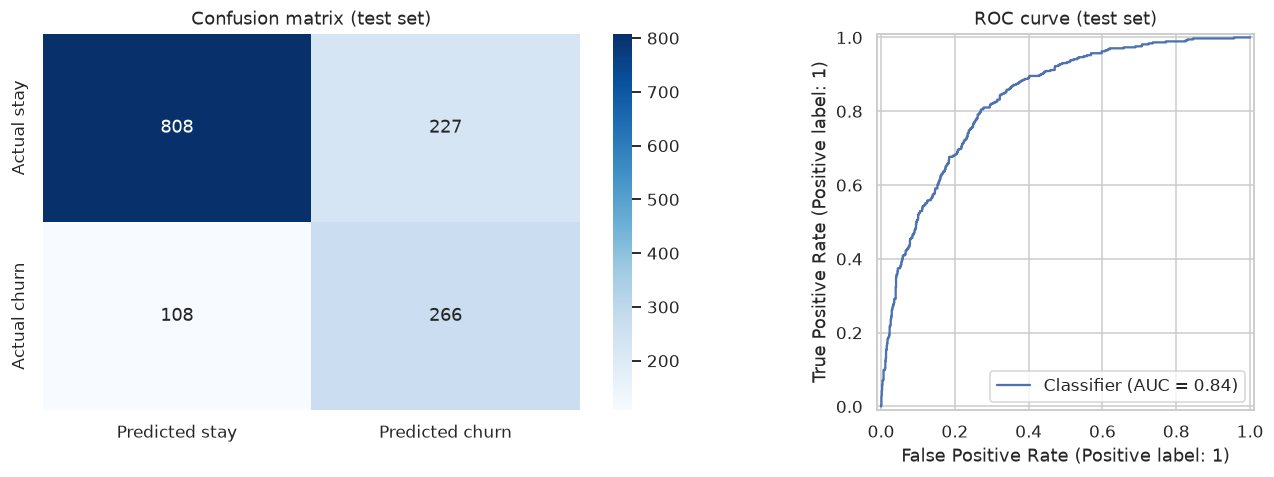

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Predicted stay", "Predicted churn"],
            yticklabels=["Actual stay", "Actual churn"])
axes[0].set_title("Confusion matrix (test set)")

RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1])
axes[1].set_title("ROC curve (test set)")
plt.tight_layout()
plt.show()

## 7. What drives churn? — feature importances

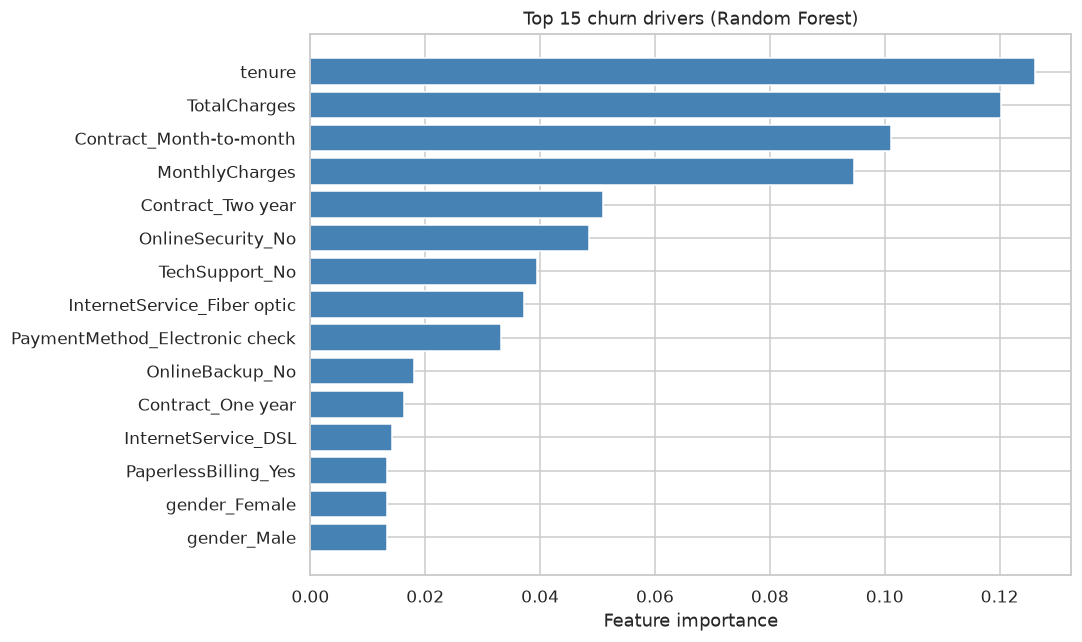

Top 5 churn drivers:
  tenure                              0.1262
  TotalCharges                        0.1203
  Contract_Month-to-month             0.1011
  MonthlyCharges                      0.0946
  Contract_Two year                   0.0509


In [13]:
importances = model.feature_importances_
order = np.argsort(importances)[::-1][:15]

plt.figure(figsize=(10, 6))
plt.barh([feature_names[i] for i in order][::-1],
         [importances[i] for i in order][::-1], color="steelblue")
plt.xlabel("Feature importance")
plt.title("Top 15 churn drivers (Random Forest)")
plt.tight_layout()
plt.show()

print("Top 5 churn drivers:")
for i in order[:5]:
    print(f"  {feature_names[i]:35s} {importances[i]:.4f}")

## 8. Conclusions

- The tuned Random Forest generalizes well to unseen customers, balancing
  precision and recall on the minority (churn) class.
- The strongest churn signals are **contract type** (month-to-month),
  **tenure**, **monthly charges**, and **internet service type** — all
  actionable levers for the retention team:
  1. Offer contract-upgrade incentives to month-to-month customers.
  2. Flag new customers (< 6 months tenure) for onboarding check-ins.
  3. Review pricing/packaging for high-monthly-charge fiber customers.
- Production artifacts live in `models/`
  (`random_forest_churn.pkl`, `preprocessor.pkl`, `metrics.json`) and are
  produced by `python src/train.py`; single-record scoring is available via
  `python src/predict.py '<json record>'`.